# 36회 후기 유형 연습 해설

공식 원문·정답이 아닌 창작 합성 자료입니다. README와 출처·보완 명세를 먼저 확인하세요. Python 3.12 별도 실행 환경을 사용합니다. 아래 문제 지문은 PDF와 같으며 설명 셀의 선택 근거·가정·가설과 실행 출력의 계산값·기각 여부·상황 결론을 함께 읽으세요. `분석코드.py`로 같은 계산을 일괄 실행할 수 있습니다.

In [1]:
from pathlib import Path
import sys
FOLDER = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
repo = next(p for p in [FOLDER]+list(FOLDER.parents) if (p/'tools/exams').is_dir())
sys.path.insert(0,str(repo/'기출문제/유형연습/공통'))
from analysis import Context
ctx=Context(FOLDER)


## 1. 연속형 예측을 이용한 후속 분류

cascade.csv는 x1~x4, 연속 target와 이진 label이다. id mod 5=0은 최종 시험이다. 두 단계 예측 유형만 참고한 창작 설정이다. label 예측 시 target 실측값은 제공되지 않으므로 학습에서도 out-of-fold 예측값만 후속 특성으로 사용한다.

### 1-1

**문제** 연속 target 예측에 학습 내부 전진 변수 선택을 적용하시오. 3-fold CV RMSE가 0.01 이상 개선될 때만 변수를 추가하고 이력·선택 변수·보류 RMSE를 제시하시오.

**풀이·선택 근거·해석**

후보 평가는 폴드 내부 대치·표준화를 포함한다. 이 절차는 CV 예측 기준이며 p-value 기반 stepwise와 구분한다. 시험 값은 선택에서 제외한다.

In [2]:
ctx.run('1-1', 'cascade_select')


=== 1-1 ===
forward CV history
[
  {
    "candidates": {
      "x1": 1.1318720775859743,
      "x2": 1.9141909733785523,
      "x3": 2.1317937956018596,
      "x4": 2.1263916241490324
    },
    "chosen": "x1",
    "RMSE": 1.1318720775859743,
    "accepted": true
  },
  {
    "candidates": {
      "x2": 0.5914108828215121,
      "x3": 1.1443427249395295,
      "x4": 1.1335431989919618
    },
    "chosen": "x2",
    "RMSE": 0.5914108828215121,
    "accepted": true
  },
  {
    "candidates": {
      "x3": 0.5926065295509466,
      "x4": 0.5922421580330213
    },
    "chosen": "x4",
    "RMSE": 0.5922421580330213,
    "accepted": false
  }
]
chosen regression
{
  "features": [
    "x1",
    "x2"
  ],
  "holdout_RMSE": 0.5842961488718758
}


### 1-2

**문제** 선택한 회귀기에 대해 학습 out-of-fold 연속 예측값과 최종 시험 예측값을 생성하시오. 자기 정답이나 in-sample 적합값을 후속 분류에 넣는 것과 비교해 누출 위험을 설명하시오.

**풀이·선택 근거·해석**

선택은 훈련 전체를 사용했으므로 OOF 값이 선택까지 완전 중첩된 무편향 성능 추정은 아니다. 최종 시험을 독립으로 두며 실제 목표 변수의 실측값은 후속 입력에서 제외한다.

In [3]:
ctx.run('1-2', 'cascade_oof')


=== 1-2 ===
OOF construction
{
  "OOF_train_rows": 192,
  "unseen_test_rows": 48,
  "input_columns": [
    "x1",
    "x2"
  ],
  "selection_nested": false
}


### 1-3

**문제** x1~x4와 예측 연속값으로 분류 파이프라인을 적합하고 최종 시험 F1·AUC·중요도와 전체 두 단계 오류 전파의 한계를 제시하시오.

**풀이·선택 근거·해석**

모형은 고정 RF로 학습하며 시험은 평가에만 쓴다. 후속 특성이 원입력에서 파생되므로 새로운 정보가 늘었다고 단정하지 않는다. 중요도는 대체 가능한 상관 특성 사이에 나뉠 수 있다.

In [4]:
ctx.run('1-3', 'cascade_classify')


=== 1-3 ===
cascade holdout
{
  "F1": 0.7346938775510204,
  "AUC": 0.7283950617283951,
  "features": [
    "x1",
    "x2",
    "x3",
    "x4",
    "predicted_target"
  ],
  "importance": [
    0.30440765920658835,
    0.13268805048060325,
    0.1261767381915783,
    0.09093724858573139,
    0.3457903035354987
  ],
  "training_ids": [
    1,
    2,
    3,
    4,
    6,
    7,
    8,
    9,
    11,
    12,
    13,
    14,
    16,
    17,
    18,
    19,
    21,
    22,
    23,
    24,
    26,
    27,
    28,
    29,
    31,
    32,
    33,
    34,
    36,
    37,
    38,
    39,
    41,
    42,
    43,
    44,
    46,
    47,
    48,
    49,
    51,
    52,
    53,
    54,
    56,
    57,
    58,
    59,
    61,
    62,
    63,
    64,
    66,
    67,
    68,
    69,
    71,
    72,
    73,
    74,
    76,
    77,
    78,
    79,
    81,
    82,
    83,
    84,
    86,
    87,
    88,
    89,
    91,
    92,
    93,
    94,
    96,
    97,
    98,
    99,
    101,
    102,
    103,
    

## 2. 중첩 응답 전처리

records.json은 일자별 records 배열과 meta.source를 가진 응답이다. 각 records 행에는 entity와 sensors(temp,load)가 있다. 모든 객체는 예제 파일에 설명된 같은 스키마를 따른다. 회고에서 JSON 전처리 유형만 확인해 내용은 새로 구성했다.

### 2-1

**문제** 중첩 JSON을 행과 열로 평탄화하고 date·source·entity·temperature·load를 갖는 표를 저장하시오. 객체 수·행 수·키·타입을 검증하시오.

**풀이·선택 근거·해석**

json_normalize의 record_path와 meta를 명시한다. 리스트 펼침과 사전 열 펼침을 구분하며 단순 문자열 eval을 쓰지 않는다.

In [5]:
ctx.run('2-1', 'json_flatten')


=== 2-1 ===
flat shape/preview
{
  "rows": 18,
  "preview": [
    {
      "index": 0,
      "date": "2024-01-01",
      "source": "simulated",
      "entity": "E1",
      "temperature": 18.343494974402024,
      "load": 4
    },
    {
      "index": 1,
      "date": "2024-01-01",
      "source": "simulated",
      "entity": "E2",
      "temperature": 22.29843369278368,
      "load": 1
    },
    {
      "index": 2,
      "date": "2024-01-01",
      "source": "simulated",
      "entity": "E3",
      "temperature": 23.326205063604373,
      "load": 1
    },
    {
      "index": 3,
      "date": "2024-01-02",
      "source": "simulated",
      "entity": "E1",
      "temperature": 22.488417847742273,
      "load": 7
    },
    {
      "index": 4,
      "date": "2024-01-02",
      "source": "simulated",
      "entity": "E2",
      "temperature": 21.83541022415154,
      "load": 7
    }
  ]
}


### 2-2

**문제** entity별 평균 온도와 일자별 총 load를 요약하시오. 중복 또는 빈 records 배열이 있을 때 집계 의미·검사 방법을 설명하시오.

**풀이·선택 근거·해석**

평탄화 전후 행 수와 키를 확인한다. 빈 배열이면 해당 날짜의 0 관측과 결측을 구분해야 하고, 중복 행은 근거 없이 합산하지 않는다.

In [6]:
ctx.run('2-2', 'json_aggregate')


=== 2-2 ===
entity mean temperature
{
  "E1": 20.128823789993145,
  "E2": 21.305211598909477,
  "E3": 20.951542955709574
}
daily total load
{
  "2024-01-01": 6,
  "2024-01-02": 23,
  "2024-01-03": 16,
  "2024-01-04": 15,
  "2024-01-05": 20,
  "2024-01-06": 20
}


## 3. 설문 잠재 구조

survey.csv는 독립 응답자 240명의 연속 근사 점수 item1~item6다. 공통 잠재 요인으로 문항 관계를 설명하려 하며 전체 자료는 탐색용이다. 정규 다변량 작업 가정을 둔다. 유지 차원 수를 정하는 두 타당한 방법을 제시하라는 유형만 확인됐고 세부 수치는 새로 만들었다.

### 3-1

**문제** 변수 간 상관과 표본 적합성을 점검하고, 상관행렬이 단위행렬인지 검정하시오. 가설·통계량·자유도·p-value·기각 여부와 표본 적합성 지표를 제시하시오.

**풀이·선택 근거·해석**

Bartlett 구형성 H0:R=I를 검정하고 KMO를 함께 본다. 유의성 하나만으로 원하는 요인 수나 구조의 적합성이 확정되지 않는다.

In [7]:
ctx.run('3-1', 'factor_suitability')


=== 3-1 ===
suitability
{
  "correlation": [
    [
      1.0,
      0.8402807012807191,
      0.8514040822471285,
      0.14299113808400232,
      0.08922530504580535,
      0.11739571251738787
    ],
    [
      0.8402807012807191,
      1.0,
      0.8457957725814119,
      0.14587201208248998,
      0.10630559022357644,
      0.1290364846956106
    ],
    [
      0.8514040822471285,
      0.8457957725814119,
      1.0,
      0.07706366294822166,
      0.040097387804227544,
      0.05594098191152924
    ],
    [
      0.14299113808400232,
      0.14587201208248998,
      0.07706366294822166,
      1.0,
      0.8613069704517574,
      0.8910202453481987
    ],
    [
      0.08922530504580535,
      0.10630559022357644,
      0.040097387804227544,
      0.8613069704517574,
      1.0,
      0.8549794167000464
    ],
    [
      0.11739571251738787,
      0.1290364846956106,
      0.05594098191152924,
      0.8910202453481987,
      0.8549794167000464,
      1.0
    ]
  ],
  "KMO": 0.775

### 3-2

**문제** 상관행렬 고유값·scree 그림과 200회 독립 열 순열의 95% 기준(seed=36)을 비교해 유지할 차원 수를 제안하시오. 두 판단 기준의 차이와 탐색적 선택의 한계를 설명하시오.

**풀이·선택 근거·해석**

scree의 꺾임과 Horn 형태의 permutation parallel analysis를 함께 본다. 고유값>1은 보조 휴리스틱이며 병렬분석의 기준 차원과 요인 수를 그대로 동일시하지 않는다.


=== 3-2 ===
parallel analysis
{
  "eigen": [
    3.019357374272095,
    2.414973443890483,
    0.16273360781191273,
    0.1545383125328115,
    0.1405585010154399,
    0.10783876047725804
  ],
  "permuted95": [
    1.3011939390636924,
    1.1643360757727426,
    1.0783887656854507,
    1.0054037922293273,
    0.9437909496280033,
    0.8623368880043244
  ],
  "retained": 2,
  "permutations": 200,
  "rule": "leading consecutive eigenvalues above matching 95th percentile"
}


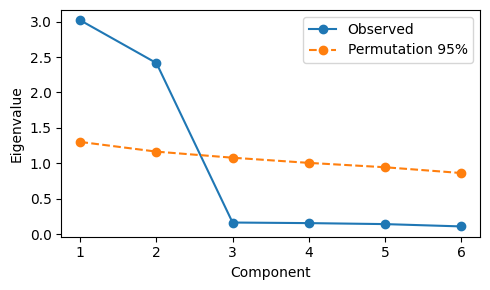

In [8]:
ctx.run('3-2', 'factor_count')

### 3-3

**문제** 선택 차원으로 공통요인 모형을 적합해 적재량·고유분산·공통성을 제시하고 회전 후 해석하시오. 주성분 분석과의 목적·오차 모형 차이를 설명하시오.

**풀이·선택 근거·해석**

FactorAnalysis(varimax)로 공통요인+문항별 고유오차를 모델링한다. PCA의 총분산 설명과 다르다. 부호·순서·회전은 유일하지 않으며 외부 표본 검증을 주장하지 않는다.

In [9]:
ctx.run('3-3', 'factor_fit')


=== 3-3 ===
factor model
{
  "factors": 2,
  "loadings": [
    [
      -0.2116105440422959,
      -0.8950581328159111
    ],
    [
      -0.22092667812494574,
      -0.8870960224545177
    ],
    [
      -0.14874784561146284,
      -0.9159590693376224
    ],
    [
      -0.944935133439467,
      0.06795525457024082
    ],
    [
      -0.9033642247273043,
      0.10715475416141731
    ],
    [
      -0.9363066658142623,
      0.08974270960804229
    ]
  ],
  "communality": [
    0.8459080834697815,
    0.8357479501619495,
    0.8611069382758949,
    0.8975203230319696,
    0.8275490638565572,
    0.8847239263760139
  ],
  "uniqueness": [
    0.15401802062060965,
    0.16407362944611914,
    0.13918635690879255,
    0.10291326456967897,
    0.1721113852585453,
    0.11525063249001244
  ],
  "covariance_RMSE": 0.00215252190767792,
  "iterations": 11
}
